In [3]:
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight

In [4]:
NUM_CLASSES = 47  # EMNIST balanced 클래스 수
BATCH_SIZE = 128
EPOCHS = 30
SEED = 42

In [5]:
# EMNIST balanced 라벨 순서 (공식 매핑)
# 0-9, A-Z, 그리고 대소문자가 헷갈리는 일부 소문자만 별도 유지
LABEL_NAMES = (
    [str(i) for i in range(10)]
    + [chr(c) for c in range(ord("A"), ord("Z") + 1)]
    + list("abdefghnqrt")  # balanced 서브셋에서 별도로 유지되는 소문자 11개
)
assert len(LABEL_NAMES) == NUM_CLASSES

In [6]:
(ds_train, ds_test), ds_info = tfds.load(
    "emnist/balanced",
    split=["train", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=True,
)

In [7]:
print("훈련 데이터 개수:", ds_info.splits["train"].num_examples)
print("테스트 데이터 개수:", ds_info.splits["test"].num_examples)

훈련 데이터 개수: 112800
테스트 데이터 개수: 18800


In [8]:
# ---------------------------------------------------------
# 2. 전처리 파이프라인
# ---------------------------------------------------------
def preprocess(image, label):
    image = tf.image.transpose(image)   # 높이/너비 축 교환 (EMNIST 방향 보정)
    # tfds의 emnist 이미지는 (28,28,1) uint8, 이미 방향이 올바르게 로드됨
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.cast(label, tf.int32)
    return image, label

In [9]:
data_augmentation = tf.keras.Sequential(
    [
    layers.RandomRotation(0.04),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomZoom(0.08),
    ]
)

In [10]:
train_ds = (
    ds_train.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(20000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (data_augmentation(x, training=True), y),
         num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    ds_test.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [11]:
# ---------------------------------------------------------
# 3. 클래스 불균형 보정을 위한 class_weight 계산
# ---------------------------------------------------------
y_train_all = np.concatenate(
    [y.numpy() for _, y in ds_train.batch(4096)], axis=0
)
classes = np.unique(y_train_all)
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train_all
)
class_weight = dict(zip(classes.tolist(), weights.tolist()))

In [12]:
del y_train_all

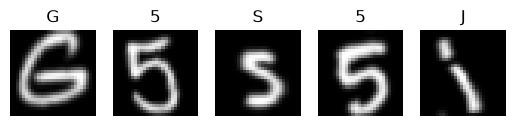

In [15]:
import matplotlib.pyplot as plt
for images, labels in train_ds.take(1):
    for i in range(5):
        plt.subplot(1, 5, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")   # images[i]로 인덱싱
        plt.title(LABEL_NAMES[labels[i].numpy()])
        plt.axis("off")
plt.show()


In [16]:
# ---------------------------------------------------------
# 5. 모델 구성 (BatchNorm + Dropout 추가)
# ---------------------------------------------------------
print("모델 만들기 +++++++++++")
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    data_augmentation,

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.15),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, padding="same", activation="relu"),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(47, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

모델 만들기 +++++++++++


In [17]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 47)             │        12,079 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,757,391 (6.70 MB)

 Trainable params: 1,757,007 (6.70 MB)

 Non-trainable params: 384 (1.50 KB)

In [18]:
# ---------------------------------------------------------
# 6. 콜백 (EarlyStopping, ReduceLROnPlateau, ModelCheckpoint)
# ---------------------------------------------------------
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_emnist_balanced_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1,
    ),
]

In [19]:
# ---------------------------------------------------------
# 7. 학습
# ---------------------------------------------------------
print("모델 훈련하기 +++++++++++")
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)
print("훈련 완료 +++++++++++")

모델 훈련하기 +++++++++++
Epoch 1/30


e:\Program\anaconda\envs\mnist_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


882/882 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.6263 - loss: 1.2533
Epoch 1: val_accuracy improved from None to 0.78287, saving model to best_emnist_balanced_cnn.keras

Epoch 1: finished saving model to best_emnist_balanced_cnn.keras
882/882 ━━━━━━━━━━━━━━━━━━━━ 195s 217ms/step - accuracy: 0.6263 - loss: 1.2533 - val_accuracy: 0.7829 - val_loss: 0.7090 - learning_rate: 0.0010
Epoch 2/30
882/882 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.7842 - loss: 0.6480
Epoch 2: val_accuracy improved from 0.78287 to 0.81654, saving model to best_emnist_balanced_cnn.keras

Epoch 2: finished saving model to best_emnist_balanced_cnn.keras
882/882 ━━━━━━━━━━━━━━━━━━━━ 188s 213ms/step - accuracy: 0.7842 - loss: 0.6480 - val_accuracy: 0.8165 - val_loss: 0.5972 - learning_rate: 0.0010
Epoch 3/30
882/882 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.8077 - loss: 0.5699
Epoch 3: val_accuracy improved from 0.81654 to 0.85957, saving model to best_emnist_balanced_cnn.keras

Epoch 3: finished 

In [20]:
# ---------------------------------------------------------
# 8. 최종 평가 및 저장
# ---------------------------------------------------------
print("최종 평가 +++++++++++")
test_loss, test_acc = model.evaluate(test_ds, verbose=2)
print(f"테스트 정확도: {test_acc:.4f}")

model.save("emnist_balanced_cnn_0811.keras")
print("모델 저장 완료: emnist_balanced_cnn.keras")

with open("emnist_balanced_labels_0811.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(LABEL_NAMES))
print("라벨 매핑 저장 완료: emnist_balanced_labels.txt")

최종 평가 +++++++++++
147/147 - 4s - 29ms/step - accuracy: 0.8596 - loss: 0.3978
테스트 정확도: 0.8596
모델 저장 완료: emnist_balanced_cnn.keras
라벨 매핑 저장 완료: emnist_balanced_labels.txt


In [ ]:
# 모델 테스트
import matplotlib.pyplot as plt

model = tf.keras.models.load_model("./lib/best_emnist_balanced_cnn.keras")
model.evaluate(test_ds)

with open("./lib/emnist_balanced_labels.txt") as f:
    saved_labels = f.read().splitlines()
print(saved_labels)

from lib.conf import label_to_char
# 2. streamlit lib/conf.py 안의 label_to_char
print(label_to_char)

# take : test_ds의 앞에서 부터 n개 가져오기
# take(1) : 배치로 되어 있기 때문에, batch 1개 가져오기

for x, y in test_ds.take(1):
    x5, y5 = x[:5], y[:5]   # 배치 안에서 앞 5개만 슬라이싱
    preds = model.predict(x5, verbose=0)

    for i in range(5):
        pred_idx = np.argmax(preds[i])
        true_idx = y5.numpy()[i]
        print(f"실제: {label_to_char[true_idx]}, 예측: {label_to_char[pred_idx]}")

        plt.subplot(1, 5, i+1)
        plt.imshow(x5[i].numpy().squeeze(), cmap="gray")
        plt.title(f"{label_to_char[true_idx]}->{label_to_char[pred_idx]}")
        plt.axis("off")
    plt.show()